### Policy Gradient Theorem и алгоритм REINFORCE

#### Параметризация стохастических стратегий

##### Дискретное пространство действий (Softmax Policy)
$$
\pi(a \mid s; \boldsymbol{\theta}) = \mathbb{P}(A_t = a \mid S_t = s; \boldsymbol{\theta}).
$$
Параметрический аппроксиматор принимает вектор состояния $s$ и формирует на выходе вектор логитов:
$$
\boldsymbol{z}(s; \boldsymbol{\theta}) = \begin{bmatrix} z(s, a_1; \boldsymbol{\theta}) & z(s, a_2; \boldsymbol{\theta}) & \dots & z(s, a_{|\mathcal{A}|}; \boldsymbol{\theta}) \end{bmatrix}^T \in \mathbb{R}^{|\mathcal{A}|}.
$$
Softmax:
$$
\pi(a \mid s; \boldsymbol{\theta}) = \frac{\exp\left(z(s, a; \boldsymbol{\theta}) / \tau\right)}{\sum\limits_{a' \in \mathcal{A}} \exp\left(z(s, a'; \boldsymbol{\theta}) / \tau\right)},
$$
Положив $\tau = 1$, запишем логарифм вероятности:
$$
\ln \pi(a \mid s; \boldsymbol{\theta}) = z(s, a; \boldsymbol{\theta}) - \ln \left( \sum_{a' \in \mathcal{A}} \exp(z(s, a'; \boldsymbol{\theta})) \right).
$$
Функция отклика (score function):
$$
\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}) = \nabla_{\boldsymbol{\theta}} z(s, a; \boldsymbol{\theta}) - \frac{\sum\limits_{a' \in \mathcal{A}} \exp(z(s, a'; \boldsymbol{\theta})) \, \nabla_{\boldsymbol{\theta}} z(s, a'; \boldsymbol{\theta})}{\sum\limits_{a' \in \mathcal{A}} \exp(z(s, a'; \boldsymbol{\theta}))} 
= \nabla_{\boldsymbol{\theta}} z(s, a; \boldsymbol{\theta}) - \sum_{a' \in \mathcal{A}} \pi(a' \mid s; \boldsymbol{\theta}) \nabla_{\boldsymbol{\theta}} z(s, a'; \boldsymbol{\theta}) 
= \nabla_{\boldsymbol{\theta}} z(s, a; \boldsymbol{\theta}) - \mathbb{E}_{a' \sim \pi(\cdot \mid s; \boldsymbol{\theta})} \left[ \nabla_{\boldsymbol{\theta}} z(s, a'; \boldsymbol{\theta}) \right].
$$

##### Непрерывное пространство действий (Gaussian Policy)
$$
\mathcal{A} = [a_{1,\min}, a_{1,\max}] \times [a_{2,\min}, a_{2,\max}] \times \dots \times [a_{m,\min}, a_{m,\max}].
$$
Параметризация стратегии через многомерное нормальное распределение:
$$
\boldsymbol{a} \sim \mathcal{N}\left(\boldsymbol{\mu}(s; \boldsymbol{\theta}_\mu), \, \boldsymbol{\Sigma}(s; \boldsymbol{\theta}_\sigma)\right).
$$
* **Вектор математического ожидания $\boldsymbol{\mu}(s; \boldsymbol{\theta}_\mu) \in \mathbb{R}^m$**  
* **Ковариационная матрица $\boldsymbol{\Sigma} \in \mathbb{R}^{m \times m}$**  
На практике полную матрицу ковариации не используют: её предполагают **диагональной**:
  $$
  \boldsymbol{\Sigma}(s) = \operatorname{diag}\left(\sigma_1^2(s), \sigma_2^2(s), \dots, \sigma_m^2(s)\right) = \begin{bmatrix}
  \sigma_1^2(s) & 0 & \dots & 0 \\
  0 & \sigma_2^2(s) & \dots & 0 \\
  \vdots & \vdots & \ddots & \vdots \\
  0 & 0 & \dots & \sigma_m^2(s)
  \end{bmatrix}.
  $$
* **Параметры $\boldsymbol{\theta} = \{\boldsymbol{\theta}_\mu, \boldsymbol{\theta}_\sigma\}$**

Для обеспечения математической корректности дисперсии $\sigma_i^2(s)$ должны быть положительными на протяжении всей оптимизации.
$$
\boldsymbol{\zeta}(s) = \ln \boldsymbol{\sigma}(s) \in \mathbb{R}^m, \quad \boldsymbol{\sigma}(s) = \exp(\boldsymbol{\zeta}(s)).
$$
В силу предположения об условной независимости компонент:
$$
\pi(a \mid s; \boldsymbol{\theta}) = \prod_{i=1}^m \frac{1}{\sqrt{2\pi}\sigma_i(s)} \exp\left( -\frac{(a_i - \mu_i(s))^2}{2\sigma_i^2(s)} \right).
$$
$$
\ln \pi(a \mid s; \boldsymbol{\theta}) = -\sum_{i=1}^m \left[ \frac{1}{2}\ln(2\pi)  +\ln \sigma_i(s) + \frac{(a_i - \mu_i(s))^2}{2\sigma_i^2(s)} \right].
$$
$$
\frac{\partial \ln \pi(a \mid s; \boldsymbol{\theta})}{\partial \mu_i(s)} = \frac{a_i - \mu_i(s)}{\sigma_i^2(s)},
$$
$$
\frac{\partial \ln \pi(a \mid s; \boldsymbol{\theta})}{\partial \zeta_i(s)} = \frac{\partial \ln \pi(a \mid s; \boldsymbol{\theta})}{\partial \sigma_i(s)} \cdot \frac{\partial \sigma_i(s)}{\partial \zeta_i(s)}
= - \left[ \frac{1}{\sigma_i(s)} - \frac{(a_i - \mu_i(s))^2}{\sigma_i^3(s)} \right] \cdot \sigma_i(s)
= \frac{(a_i - \mu_i(s))^2}{\sigma_i^2(s)} - 1.
$$
Итоговый градиент по вектору весов модели $\boldsymbol{\theta}$:
$$
\begin{aligned}
\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}) 
&= \sum_{i=1}^m \left[\frac{\partial \ln \pi(a \mid s; \boldsymbol{\theta})}{\partial \mu_i(s)} \cdot \nabla_{\boldsymbol{\theta}} \mu_i(s) + \frac{\partial \ln \pi(a \mid s; \boldsymbol{\theta})}{\partial \zeta_i(s)} \cdot \nabla_{\boldsymbol{\theta}} \zeta_i(s)\right] \\
&= \sum_{i=1}^m \nabla_{\boldsymbol{\theta}} \mu_i(s) \left( \frac{a_i - \mu_i(s)}{\sigma_i^2(s)} \right) + \sum_{i=1}^m \nabla_{\boldsymbol{\theta}} \zeta_i(s) \left( \frac{(a_i - \mu_i(s))^2}{\sigma_i^2(s)} - 1 \right) \\
&= \frac{\partial \boldsymbol{\mu}(s)}{\partial \boldsymbol{\theta}^T} \frac{\boldsymbol{a} - \boldsymbol{\mu}(s)}{\boldsymbol{\sigma}^2(s)} + \frac{\partial \boldsymbol{\zeta}(s)}{\partial \boldsymbol{\theta}^T} \left( \frac{(\boldsymbol{a} - \boldsymbol{\mu}(s))^2}{\boldsymbol{\sigma}^2(s)} - \mathbf{1} \right).
\end{aligned}
$$


#### Теорема о градиенте стратегии (Policy Gradient Theorem)

> **Лемма о причинности (занулении прошлых наград)**
> 
> Пусть $G_{0:t-1} = \sum\limits_{k=0}^{t-1} \gamma^k r_{k+1}$ — сумма наград, полученных агентом до совершения действия $a_t$. Тогда
> $$
\mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ G_{0:t-1} \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right] = \mathbf{0}.
$$
> 
> **Доказательство**
> 
> Применим закон полного математического ожидания, обусловив процесс по предыстории $h_t = (s_0, a_0, r_1, \dots, s_t)$ вплоть до момента выбора действия $a_t$:
>$$
\mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ G_{0:t-1} \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right] = \mathbb{E}_{h_t} \left[ \mathbb{E}_{a_t \sim \pi(\cdot \mid s_t; \boldsymbol{\theta})} \left[ G_{0:t-1} \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \;\middle|\; h_t \right] \right].
$$
> Величина $G_{0:t-1}$ полностью детерминирована историей $h_t$:
> $$
\mathbb{E}_{a_t \sim \pi(\cdot \mid s_t; \boldsymbol{\theta})} \left[ G_{0:t-1} \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \;\middle|\; h_t \right] = G_{0:t-1} \mathbb{E}_{a_t \sim \pi(\cdot \mid s_t; \boldsymbol{\theta})} \left[ \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \;\middle|\; s_t \right].
$$
> $$
\mathbb{E}_{a_t \sim \pi(\cdot \mid s_t; \boldsymbol{\theta})} \left[ \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \mid s_t \right] = \int\limits_{\mathcal{A}} \pi(a_t \mid s_t; \boldsymbol{\theta}) \frac{\nabla_{\boldsymbol{\theta}} \pi(a_t \mid s_t; \boldsymbol{\theta})}{\pi(a_t \mid s_t; \boldsymbol{\theta})} da_t
= \int\limits_{\mathcal{A}} \nabla_{\boldsymbol{\theta}} \pi(a_t \mid s_t; \boldsymbol{\theta}) da_t
= \nabla_{\boldsymbol{\theta}} \left( \int\limits_{\mathcal{A}} \pi(a_t \mid s_t; \boldsymbol{\theta}) da_t \right) = \nabla_{\boldsymbol{\theta}} (1) = \boldsymbol{0}.
$$

> **Теорема о градиенте стратегии (Policy Gradient Theorem, Sutton et al., 1999)**
> 
> Для любого дифференцируемого семейства стохастических стратегий $\pi(a \mid s; \boldsymbol{\theta})$ верно
> $$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ \sum_{t=0}^{T-1} \gamma^t Q^{\pi_{\boldsymbol{\theta}}}(s_t, a_t) \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right].
$$
> 
> **Доказательство**
> 
> $$
\begin{aligned}
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) &= \nabla_{\boldsymbol{\theta}} \mathbb{E}_{\tau \sim p(\tau; \boldsymbol{\theta})}[G_0(\tau)] = \int G_0(\tau) \nabla_{\boldsymbol{\theta}} p(\tau; \boldsymbol{\theta}) d\tau \\
&= \int G_0(\tau) \left( p(\tau; \boldsymbol{\theta}) \nabla_{\boldsymbol{\theta}} \ln p(\tau; \boldsymbol{\theta}) \right) d\tau = \mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ G_0(\tau) \nabla_{\boldsymbol{\theta}} \ln p(\tau; \boldsymbol{\theta}) \right].
\end{aligned}
$$
> Логарифм плотности траектории $p(\tau; \boldsymbol{\theta})$:
> $$
\ln p(\tau; \boldsymbol{\theta}) = \ln \rho_0(s_0) + \sum_{t=0}^{T-1} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) + \sum_{t=0}^{T-1} \ln p(s_{t+1}, r_{t+1} \mid s_t, a_t).
$$
> Так как начальное распределение $\rho_0$ и динамика среды $p$ не зависят от параметров стратегии $\boldsymbol{\theta}$, их производные по параметрам равны нулю.
> $$
\nabla_{\boldsymbol{\theta}} \ln p(\tau; \boldsymbol{\theta}) = \sum_{t=0}^{T-1} \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}).
$$
> Подставим эту сумму в выражение для градиента:
> $$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ \sum_{t=0}^{T-1} G_0(\tau) \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right].
$$
> Разобьем полную кумулятивную награду на прошлую и будущую части: $G_0 = G_{0:t-1} + \gamma^t G_t$. В силу леммы о причинности вклад прошлых наград зануляется:
>  $$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ \sum_{t=0}^{T-1} \gamma^t G_t \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right].
$$
> Применим закон полного математического ожидания к каждому слагаемому, зафиксировав пару $(s_t, a_t)$. Вектор $\nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t ; \boldsymbol{\theta})$ при этом становится константой, а случайной остаётся только будущая кумулятивная награда $G_t$:
>  $$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ \sum_{t=0}^{T-1} \gamma^t Q^{\pi_{\boldsymbol{\theta}}}(s_t, a_t) \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right].
$$

> **Обобщение на бесконечный горизонт**
> 
> В задачах без терминальных состояний горизонт взаимодействия бесконечен:
> $$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ \sum_{t=0}^{\infty} \gamma^t Q^{\pi_{\boldsymbol{\theta}}}(s_t, a_t) \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right].
$$
> Внесем математическое ожидание под знак суммы. На каждом шаге $t$ ожидание раскрывается через распределение состояний и условное распределение действий:
> $$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \sum_{s \in \mathcal{S}} \left( \sum_{t=0}^{\infty} \gamma^t \mathbb{P}(S_t = s \mid s_0 \sim \rho_0, \pi_{\boldsymbol{\theta}}) \right) \sum_{a \in \mathcal{A}} \pi(a \mid s; \boldsymbol{\theta}) Q^{\pi_{\boldsymbol{\theta}}}(s, a) \nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}).
$$
> Сумма в скобках представляет собой дисконтированное число посещений состояния $s$ за бесконечное число шагов. Обозначим ее как $\eta(s)$.
> $$
\sum_{s \in \mathcal{S}} \eta(s) = \sum_{t=0}^{\infty} \gamma^t \sum_{s \in \mathcal{S}} \mathbb{P}(S_t = s \mid s_0 \sim \rho_0, \pi_{\boldsymbol{\theta}}) = \sum_{t=0}^{\infty} \gamma^t \cdot 1 = \frac{1}{1 - \gamma}.
$$
> Ддисконтированное on-policy распределение состояний:
> $$
d^{\pi_{\boldsymbol{\theta}}}(s) = (1 - \gamma) \eta(s), \quad \sum_{s \in \mathcal{S}} d^{\pi_{\boldsymbol{\theta}}}(s) = 1.
$$
> Подставим $\eta(s) = d^{\pi_{\boldsymbol{\theta}}}(s) / (1 - \gamma)$ в выражение для градиента:
> $$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \frac{1}{1 - \gamma} \mathbb{E}_{s \sim d^{\pi_{\boldsymbol{\theta}}}, \, a \sim \pi_{\boldsymbol{\theta}}} \left[ Q^{\pi_{\boldsymbol{\theta}}}(s, a) \nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}) \right].
$$
> Практический смысл:
> 1. **Уход от временной шкалы**
> 2. **Теоретический фундамент пошагового обучения (Actor-Critic)**

#### REINFORCE

Пусть на $k$-м шаге оптимизации агент, следуя текущей стратегии $\pi_{\boldsymbol{\theta}_k}$, сгенерировал траекторию длины $T$. Тогда стохастическая выборочная оценка градиента по данному эпизоду принимает вид:
$$
\hat{\nabla}_{\boldsymbol{\theta}} J(\boldsymbol{\theta}_k) = \sum_{t=0}^{T-1} \gamma^t G_t \nabla_{\boldsymbol{\theta}} \left. \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right|_{\boldsymbol{\theta} = \boldsymbol{\theta}_k}, \quad
\boldsymbol{\theta}_{k+1} = \boldsymbol{\theta}_k + \alpha \hat{\nabla}_{\boldsymbol{\theta}} \left. J(\boldsymbol{\theta})\right|_{\boldsymbol{\theta} = \boldsymbol{\theta}_k},
$$
Вектор параметров можно обновлять суммарно один раз за весь эпизод или инкрементально, накапливая пошаговые поправки вдоль траектории. Множитель дисконтирования $\gamma^t$ опускают.

Ключевые недостатки:

1. Экстремально высокая дисперсия градиентных оценок
2. Чувствительность к шкале и знаку наград среды

#### Baseline

$$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ \sum_{t=0}^{T-1} \gamma^t \left( Q^{\pi_{\boldsymbol{\theta}}}(s_t, a_t) - b(s_t) \right) \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right].
$$

> **Теорема о несмещённости базовой линии**
> 
> Для любой функции $b: \mathcal{S} \to \mathbb{R}$, зависящей произвольным образом от состояния $s$, верно:
> $$
\mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ b(s_t) \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right] = \mathbf{0}.
$$
>
> **Доказательство**
> Применим закон полного математического ожидания, зафиксировав состояние $s_t$:
> $$
\mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ b(s_t) \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right] = \mathbb{E}_{s_t} \left[ \mathbb{E}_{a_t \sim \pi(\cdot \mid s_t; \boldsymbol{\theta})} \left[ b(s_t) \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \;\middle|\; s_t \right] \right].
$$
> Вынесем $b(s_t)$ за знак внутреннего математического ожидания, после чего раскроем его через интеграл по мере распределения действий:
> $$
\mathbb{E}_{a_t \sim \pi(\cdot \mid s_t; \boldsymbol{\theta})} \left[ \nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \mid s_t \right] = \int\limits_{\mathcal{A}} \pi(a_t \mid s_t; \boldsymbol{\theta}) \frac{\nabla_{\boldsymbol{\theta}} \pi(a_t \mid s_t; \boldsymbol{\theta})}{\pi(a_t \mid s_t; \boldsymbol{\theta})} da_t
= \int\limits_{\mathcal{A}} \nabla_{\boldsymbol{\theta}} \pi(a_t \mid s_t; \boldsymbol{\theta}) da_t
= \nabla_{\boldsymbol{\theta}} \left( \int\limits_{\mathcal{A}} \pi(a_t \mid s_t; \boldsymbol{\theta}) da_t \right) = \nabla_{\boldsymbol{\theta}} (1) = \boldsymbol{0}.
$$

Задача **минимизации дисперсии выборочной оценки градиента**. Стохастическая оценка градиента для одного шага имеет вид:
$$
\boldsymbol{g}(a) = \left( Q(s, a) - b(s) \right) \nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta}).
$$
Необходимо найти такое скалярное значение базовой линии $b(s)$, при котором след ковариационной матрицы $\operatorname{tr}(\mathbb{D}[\boldsymbol{g}(a)])$  минимален.
$$
\operatorname{tr}(\mathbb{D}[\boldsymbol{g}(a)]) = \mathbb{E}_{a \sim \pi} \left[ \Vert{}\boldsymbol{g}(a)\Vert{}_2^2 \right] - \Vert{}\mathbb{E}_{a \sim \pi}[\boldsymbol{g}(a)]\Vert{}_2^2.
$$
Второе слагаемое $\Vert{}\mathbb{E}_{a \sim \pi}[\boldsymbol{g}(a)]\Vert{}_2^2$ не зависит от $b(s)$, следовательно:
$$
\underset{b(s)}{\operatorname{argmin}}\operatorname{tr}(\mathbb{D}[\boldsymbol{g}(a)]) = \underset{b(s)}{\operatorname{argmin}}\mathbb{E}_{a \sim \pi} \left[ \Vert{}\boldsymbol{g}(a)\Vert{}_2^2 \right].
$$

$$
\|\boldsymbol{g}(a)\|_2^2 = \left( Q(s, a)^2 - 2b(s)Q(s, a) + b^2(s) \right) \|\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta})\|_2^2.
$$
Вынесем функцию $b(s)$ за знак математического ожидания и запишем целевую функцию $J(b(s))$:
$$
J(b(s)) = \mathbb{E}_{a \sim \pi} \left[ Q(s, a)^2 \|\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta})\|_2^2 \right] -
2b(s) \mathbb{E}_{a \sim \pi} \left[ Q(s, a) \|\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta})\|_2^2 \right]+
b^2(s) \mathbb{E}_{a \sim \pi} \left[ \|\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta})\|_2^2 \right].
$$
Коэффициент при старшей степени $\mathbb{E}_{a \sim \pi} \left[ \|\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta})\|_2^2 \right] > 0$, что гарантирует наличие глобального минимума.
$$
\frac{d J(b(s))}{d b(s)} = -2 \mathbb{E}_{a \sim \pi} \left[ Q(s, a) \|\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta})\|_2^2 \right] + 2b(s) \mathbb{E}_{a \sim \pi} \left[ \|\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta})\|_2^2 \right].
$$
Теоретически оптимальный baseline $b^*(s)$:
$$
b^*(s) = \frac{\mathbb{E}_{a \sim \pi} \left[ Q(s, a) \, \|\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta})\|_2^2 \right]}{\mathbb{E}_{a \sim \pi} \left[ \|\nabla_{\boldsymbol{\theta}} \ln \pi(a \mid s; \boldsymbol{\theta})\|_2^2 \right]}.
$$
$$
b^{*}(s)\approx \mathbb{E}_{a\sim \pi }[Q(s,a)]=V^{\pi }(s).
$$
$$
\nabla_{\boldsymbol{\theta}} J(\boldsymbol{\theta}) = \mathbb{E}_{\tau \sim p(\cdot; \boldsymbol{\theta})} \left[ \sum_{t=0}^{T-1} \gamma^t A^{\pi_{\boldsymbol{\theta}}}(s_t, a_t)\nabla_{\boldsymbol{\theta}} \ln \pi(a_t \mid s_t; \boldsymbol{\theta}) \right].
$$

#### REINFORCE with Baseline

Параллельно со стратегией вводится параметрический аппроксиматор ценности состояния $V(s; \boldsymbol{\varphi})$, где $\boldsymbol{\varphi} \in \mathbb{R}^p$ — вектор весов аппроксиматора.
1. Аппроксиматор стратегии $\pi(a \mid s; \boldsymbol{\theta})$ с параметрами $\boldsymbol{\theta}$;
2. Аппроксиматор базовой линии $V(s; \boldsymbol{\varphi})$ с параметрами $\boldsymbol{\varphi}$.

1. **Оценка преимущества на шаге $\boldsymbol t$**
    $$
    \delta_t = G_t - V(s_t; \boldsymbol{\varphi}).
    $$
2. **Обновление параметров базовой линии $\boldsymbol{\varphi}$**
    Минимизация среднеквадратичной ошибки прогнозирования кумулятивной награды $(G_t - V(s_t; \boldsymbol{\varphi}))^2 / 2$:
	$$
	\boldsymbol{\varphi}_{k+1} = \boldsymbol{\varphi}_k + \beta \sum_{t=0}^{T-1} \left(G_t-V(s_t;\boldsymbol{\varphi}_k)\right) \left.\nabla_{\boldsymbol{\varphi}}V(s_t;\boldsymbol{\varphi})\right|_{\boldsymbol{\varphi}=\boldsymbol{\varphi}_k}.
	$$
3. **Обновление параметров стратегии $\boldsymbol{\theta}$**
	$$
	 \boldsymbol{\theta}_{k+1} = \boldsymbol{\theta}_k + \alpha\sum_{t=0}^{T-1} \gamma^t\left(G_t-V(s_t;\boldsymbol{\varphi}_k)\right) \left.\nabla_{\boldsymbol{\theta}}\ln\pi(a_t\mid s_t;\boldsymbol{\theta})\right|_{\boldsymbol{\theta}=\boldsymbol{\theta}_k},
	 $$

In [1]:
import random
import time
from typing import Dict, List, Tuple
from IPython import display

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical, Normal

sns.set_theme(style="whitegrid")
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}\usepackage{amsfonts}'
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10
})

%config InlineBackend.figure_format = 'svg'

In [2]:
class DiscretePolicyNetwork(nn.Module):
    """
    Параметризация стохастической дискретной стратегии (Softmax Policy).
    Принимает вектор состояния s, возвращает категориальное распределение по действиям.
    """
    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, state: torch.Tensor) -> Categorical:
        logits = self.net(state)
        # Softmax вычисляется внутри распределения Categorical
        return Categorical(logits=logits)

        
class GaussianPolicyNetwork(nn.Module):
    """
    Параметризация непрерывной стратегии через нормальное распределение (Gaussian Policy).
    Вычисляет математическое ожидание \mu(s) и вектор логарифма стандартного отклонения \zeta = \ln(\sigma).
    """
    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )
        # Голова математического ожидания mu(s)
        self.mu_head = nn.Linear(hidden_dim, action_dim)
        
        # Вектор логарифмов стандартных отклонений: zeta_i = ln(sigma_i).
        # В практических реализациях разброс действий (уровень исследования среды) 
        # задается единым для всех состояний: sigma не зависит от s.
        # Конструктор nn.Parameter превращает обычный тензор в обучаемый вес модели:
        # 1. Он автоматически попадает в policy_net.parameters().
        # 2. Оптимизатор Adam обновляет его градиентным спуском так же, как веса линейных слоев.
        # 3. Начальное значение 0.0 задает начальный разброс sigma = exp(0) = 1.0.
        self.log_std = nn.Parameter(torch.zeros(action_dim))

    def forward(self, state: torch.Tensor) -> Normal:
        features = self.backbone(state)
        mu = self.mu_head(features)
        std = torch.exp(self.log_std)
        return Normal(loc=mu, scale=std)


class ValueNetwork(nn.Module):
    """
    Параметрический аппроксиматор функции ценности состояния V(s; \varphi),
    используемый в качестве Baseline для снижения дисперсии.
    """
    def __init__(self, state_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        return self.net(state)


class REINFORCEAgent:
    """
    Реализует алгоритм REINFORCE и REINFORCE with Baseline.
    """
    def __init__(
        self,
        state_dim: int,
        action_dim: int,
        is_continuous: bool = False,
        use_baseline: bool = True,
        lr_policy: float = 3e-4,   # 3e-4 для стабильности непрерывных сред
        lr_value: float = 1e-3,    # 1e-3 для критика
        gamma: float = 0.99
    ):
        self.is_continuous = is_continuous
        self.use_baseline = use_baseline
        self.gamma = gamma

        if is_continuous:
            self.policy_net = GaussianPolicyNetwork(state_dim, action_dim)
        else:
            self.policy_net = DiscretePolicyNetwork(state_dim, action_dim)

        self.policy_optimizer = optim.Adam(self.policy_net.parameters(), lr=lr_policy)

        if self.use_baseline:
            self.value_net = ValueNetwork(state_dim)
            self.value_optimizer = optim.Adam(self.value_net.parameters(), lr=lr_value)
            self.value_loss_fn = nn.MSELoss()

        self.states: List[np.ndarray] = []
        self.actions: List[any] = []
        self.rewards: List[float] = []

    def select_action(self, state: np.ndarray, evaluate: bool = False):
        state_t = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
        dist = self.policy_net(state_t)
        
        if evaluate:
            if self.is_continuous:
                action = dist.mean
            else:
                action = dist.probs.argmax(dim=-1)
        else:
            action = dist.sample()

        if self.is_continuous:
            return action.squeeze(0).detach().cpu().numpy()
        return int(action.item())

    def store_transition(self, state: np.ndarray, action: any, reward: float):
        self.states.append(state)
        self.actions.append(action)
        self.rewards.append(reward)

    def update(self) -> float:
        T = len(self.rewards)
        if T == 0:
            return 0.0

        # Рекуррентный расчёт фактической кумулятивной награды G_t
        returns = np.zeros(T, dtype=np.float32)
        G = 0.0
        for t in reversed(range(T)):
            G = self.rewards[t] + self.gamma * G
            returns[t] = G

        states_t = torch.tensor(np.array(self.states), dtype=torch.float32)
        returns_t = torch.tensor(returns, dtype=torch.float32).unsqueeze(1)
        
        if self.is_continuous:
            actions_t = torch.tensor(np.array(self.actions), dtype=torch.float32)
        else:
            actions_t = torch.tensor(np.array(self.actions), dtype=torch.int64)

        # Вычисление базовой линии и преимущества
        if self.use_baseline:
            # Обучаем критика V(s; \varphi) делать несколько шагов по траектории
            for _ in range(3):
                values_t = self.value_net(states_t)
                value_loss = 0.5 * self.value_loss_fn(values_t, returns_t)
                self.value_optimizer.zero_grad()
                value_loss.backward()
                self.value_optimizer.step()

            with torch.no_grad():
                values_t = self.value_net(states_t)
                reinforce_signal = returns_t - values_t
        else:
            reinforce_signal = returns_t

        # Логарифмы вероятностей \ln \pi(a_t | s_t)
        dist = self.policy_net(states_t)
        if self.is_continuous:
            log_probs = dist.log_prob(actions_t).sum(dim=-1, keepdim=True)
        else:
            log_probs = dist.log_prob(actions_t).unsqueeze(1)

        # Практическая форма REINFORCE: дисконтирование учтено внутри G_t,
        # искусственное затухание \gamma^t перед логарифмом снято
        policy_loss = -torch.sum(reinforce_signal * log_probs)

        self.policy_optimizer.zero_grad()
        policy_loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy_net.parameters(), max_norm=2.0)
        self.policy_optimizer.step()

        self.states.clear()
        self.actions.clear()
        self.rewards.clear()

        return float(policy_loss.item())


def train_reinforce(
    env_name: str,
    agent_name: str,
    agent: REINFORCEAgent,
    episodes: int = 250,
    log_freq: int = 25,
    **env_kwargs  # Дополнительные аргументы среды (пороги, диапазоны)
) -> Dict[str, any]:
    """
    Обучающий цикл метода Монте-Карло.
    """
    env = gym.make(env_name)
    rewards_history = []

    t_start = time.time()
    t_last_log = t_start
    print(agent_name)

    for ep in range(episodes):
        state, info = env.reset()
        episode_reward = 0.0
        done = False

        while not done:
            action = agent.select_action(state, evaluate=False)
            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            agent.store_transition(state, action, reward)
            state = next_state
            episode_reward += reward

        # Обновление параметров выполняется один раз в конце эпизода
        agent.update()
        rewards_history.append(episode_reward)

        if (ep + 1) % log_freq == 0 or (ep + 1) == episodes:
            avg_r = np.mean(rewards_history[-log_freq:])
            t_now = time.time()
            interval_time = t_now - t_last_log
            t_last_log = t_now

            print(
                f"Эпизод {ep + 1:3d}/{episodes} | "
                f"Время с прошлого вывода: {interval_time:5.1f} с | "
                f"Средняя награда ({min(log_freq, len(rewards_history))} эп.): "
                f"{avg_r:6.1f}"
            )

    total_time = time.time() - t_start
    env.close()
    print(f"{agent_name} завершён за {total_time:.1f} с.\n")

    return {
        "name": agent_name,
        "rewards": np.array(rewards_history),
        "time": total_time,
        "agent": agent
    }

#### CartPole-v1

CartPole-v1
REINFORCE (Vanilla)
Эпизод  25/250 | Время с прошлого вывода:   0.4 с | Средняя награда (25 эп.):   21.4
Эпизод  50/250 | Время с прошлого вывода:   0.5 с | Средняя награда (25 эп.):   29.8
Эпизод  75/250 | Время с прошлого вывода:   0.3 с | Средняя награда (25 эп.):   29.6
Эпизод 100/250 | Время с прошлого вывода:   0.3 с | Средняя награда (25 эп.):   34.2
Эпизод 125/250 | Время с прошлого вывода:   0.4 с | Средняя награда (25 эп.):   44.8
Эпизод 150/250 | Время с прошлого вывода:   0.4 с | Средняя награда (25 эп.):   35.3
Эпизод 175/250 | Время с прошлого вывода:   0.3 с | Средняя награда (25 эп.):   26.0
Эпизод 200/250 | Время с прошлого вывода:   0.2 с | Средняя награда (25 эп.):   18.2
Эпизод 225/250 | Время с прошлого вывода:   0.2 с | Средняя награда (25 эп.):   12.5
Эпизод 250/250 | Время с прошлого вывода:   0.1 с | Средняя награда (25 эп.):    9.7
REINFORCE (Vanilla) завершён за 3.2 с.

REINFORCE with Baseline
Эпизод  25/250 | Время с прошлого вывода:   0.5 с | Ср

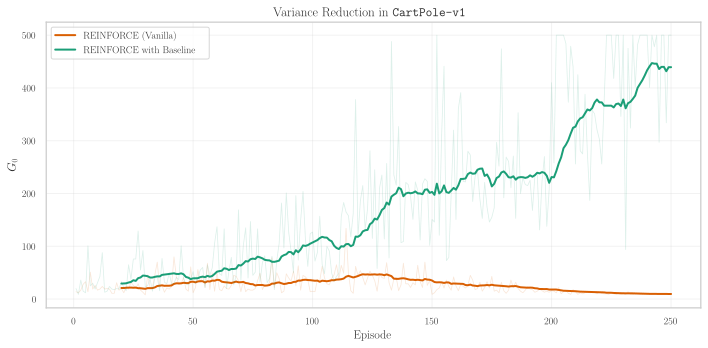

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ENV_ID_CARTPOLE = "CartPole-v1"
EPISODES_CARTPOLE = 250

env = gym.make(ENV_ID_CARTPOLE)
s_dim = env.observation_space.shape[0]
a_dim = env.action_space.n
env.close()

# 1. REINFORCE without Baseline
agent_vanilla = REINFORCEAgent(
    state_dim=s_dim,
    action_dim=a_dim,
    is_continuous=False,
    use_baseline=False,
    lr_policy=1e-3
)

# 2. REINFORCE with Baseline
agent_baseline = REINFORCEAgent(
    state_dim=s_dim,
    action_dim=a_dim,
    is_continuous=False,
    use_baseline=True,
    lr_policy=1e-3,
    lr_value=2e-3
)

print(f"{'='*70}\n{ENV_ID_CARTPOLE}\n{'='*70}")
res_cartpole_vanilla = train_reinforce(ENV_ID_CARTPOLE, "REINFORCE (Vanilla)", agent_vanilla, episodes=EPISODES_CARTPOLE)
res_cartpole_baseline = train_reinforce(ENV_ID_CARTPOLE, "REINFORCE with Baseline", agent_baseline, episodes=EPISODES_CARTPOLE)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#d95f02", "#1b9e77"]
window = 20

for idx, res in enumerate([res_cartpole_vanilla, res_cartpole_baseline]):
    rewards = res["rewards"]
    name = res["name"]
    color = colors[idx]
    
    # Сырые награды
    ax.plot(np.arange(1, len(rewards) + 1), rewards, color=color, alpha=0.15, lw=0.8)
    
    # Скользящее среднее
    if len(rewards) >= window:
        ma = np.convolve(rewards, np.ones(window) / window, mode="valid")
        ax.plot(np.arange(window, len(rewards) + 1), ma, color=color, lw=2.0, label=name)
    else:
        ax.plot(np.arange(1, len(rewards) + 1), rewards, color=color, lw=1.5, label=name)

ax.set_title(rf"Variance Reduction in \texttt{{{ENV_ID_CARTPOLE}}}")
ax.set_xlabel("Episode")
ax.set_ylabel(r"$G_0$")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

#### Hopper-v5

Hopper-v5
REINFORCE with Baseline
Эпизод 200/4000 | Время с прошлого вывода:   6.2 с | Средняя награда (200 эп.):   58.2
Эпизод 400/4000 | Время с прошлого вывода:  11.3 с | Средняя награда (200 эп.):  142.0
Эпизод 600/4000 | Время с прошлого вывода:  12.4 с | Средняя награда (200 эп.):  205.1
Эпизод 800/4000 | Время с прошлого вывода:  19.8 с | Средняя награда (200 эп.):  311.2
Эпизод 1000/4000 | Время с прошлого вывода:  19.7 с | Средняя награда (200 эп.):  334.5
Эпизод 1200/4000 | Время с прошлого вывода:  16.6 с | Средняя награда (200 эп.):  314.4
Эпизод 1400/4000 | Время с прошлого вывода:  17.2 с | Средняя награда (200 эп.):  342.5
Эпизод 1600/4000 | Время с прошлого вывода:  18.7 с | Средняя награда (200 эп.):  391.5
Эпизод 1800/4000 | Время с прошлого вывода:  20.1 с | Средняя награда (200 эп.):  459.8
Эпизод 2000/4000 | Время с прошлого вывода:  22.0 с | Средняя награда (200 эп.):  526.7
Эпизод 2200/4000 | Время с прошлого вывода:  20.2 с | Средняя награда (200 эп.):  451.2
Эп

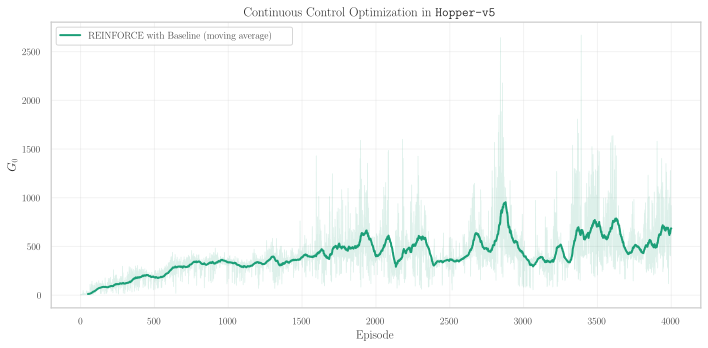

In [4]:
ENV_ID_HOPPER = "Hopper-v5"
NUM_EPISODES_HOPPER = 4000

env = gym.make(ENV_ID_HOPPER)
s_dim = env.observation_space.shape[0]
a_dim = env.action_space.shape[0]
env.close()

agent = REINFORCEAgent(
    state_dim=s_dim,
    action_dim=a_dim,
    is_continuous=True,
    use_baseline=True,
    lr_policy=3e-4,
    lr_value=1e-3
)

print(f"{'='*70}\n{ENV_ID_HOPPER}\n{'='*70}")
# Запуск обучения Hopper с расширенным коридором устойчивости:
# hopper_kwargs = {
#     "healthy_angle_range": (-0.8, 0.8),    # наклон до ~45 градусов
#     "healthy_z_range": (0.4, float("inf")) # приседание до 40 см от пола
# }

# Вариант без досрочного прерывания по падению:
hopper_kwargs = {
    "terminate_when_unhealthy": False
}

res_hopper_baseline = train_reinforce(ENV_ID_HOPPER, "REINFORCE with Baseline", agent, episodes=NUM_EPISODES_HOPPER, log_freq=200, **hopper_kwargs)

fig, ax = plt.subplots(figsize=(10, 5))
color = "#1b9e77"
window = 50

rewards = res_hopper_baseline["rewards"]
name = res_hopper_baseline["name"]

# Сырые награды
ax.plot(np.arange(1, len(rewards) + 1), rewards, color=color, alpha=0.15, lw=0.8)

# Скользящее среднее
if len(rewards) >= window:
    ma = np.convolve(rewards, np.ones(window) / window, mode="valid")
    ax.plot(np.arange(window, len(rewards) + 1), ma, color=color, lw=2.0, label=f"{name} (moving average)")
else:
    ax.plot(np.arange(1, len(rewards) + 1), rewards, color=color, lw=1.5, label=name)

ax.set_title(rf"Continuous Control Optimization in \texttt{{{ENV_ID_HOPPER}}}")
ax.set_xlabel("Episode")
ax.set_ylabel(r"$G_0$")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

Демонстрация: CartPole-v1 (простая эвристика)


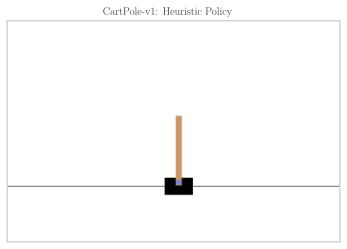

G_0 = 500.00 | шагов: 500

Демонстрация: Hopper-v5 (простая эвристика)


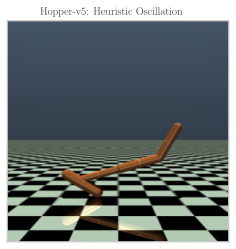

G_0 = 84.75 | шагов: 400



In [5]:
# =====================================================================
# Эвристические стратегии
# =====================================================================

def heuristic_action_cartpole(state: np.ndarray) -> int:
    """
    ПД-регулятор угла наклона и угловой скорости шеста.
    x, v, theta, omega = state
    """
    theta, omega = state[2], state[3]
    # Если шест падает вправо — толкаем тележку вправо (1), иначе влево (0)
    return 1 if (theta + 0.1 * omega) > 0 else 0


def heuristic_action_hopper(step_idx: int) -> np.ndarray:
    """
    Периодический синусоидальный генератор движения шарниров (без обратной связи).
    Имитирует нескоординированные попытки отталкивания.
    """
    t = step_idx * 0.1
    thigh = 1 * np.sin(t)        # Бедро
    leg = 0.6 * np.abs(np.sin(t))  # Колено
    foot = 0.5 * np.cos(t)         # Стопа
    return np.array([thigh, leg, foot], dtype=np.float32)


# -------------------------------------------------------------
# Анимация CartPole-v1 с эвристической стратегией
# -------------------------------------------------------------
print("Демонстрация: CartPole-v1 (простая эвристика)")
env = gym.make(ENV_ID_CARTPOLE, render_mode="rgb_array")
state, info = env.reset(seed=SEED)
episode_return = 0.0
episode_steps = 0

fig, ax = plt.subplots(figsize=(6, 4))
img = ax.imshow(env.render())
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(r"CartPole-v1: Heuristic Policy", fontsize=11)

display_handle = display.display(fig, display_id=True)

for _ in range(500):
    action = heuristic_action_cartpole(state)
    state, reward, terminated, truncated, info = env.step(action)
    episode_return += reward
    episode_steps += 1
    
    img.set_data(env.render())
    display_handle.update(fig)
    
    if terminated or truncated:
        break

plt.close(fig)
env.close()
print(f"G_0 = {episode_return:.2f} | шагов: {episode_steps}\n")


# -------------------------------------------------------------
# Анимация Hopper-v5 с эвристической стратегией
# -------------------------------------------------------------
print("Демонстрация: Hopper-v5 (простая эвристика)")
env = gym.make(ENV_ID_HOPPER, render_mode="rgb_array", **hopper_kwargs)
state, info = env.reset(seed=SEED)
episode_return = 0.0
episode_steps = 0

fig, ax = plt.subplots(figsize=(6, 4))
img = ax.imshow(env.render())
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(r"Hopper-v5: Heuristic Oscillation", fontsize=11)

display_handle = display.display(fig, display_id=True)

for step_k in range(400):
    action = heuristic_action_hopper(step_k)
    state, reward, terminated, truncated, info = env.step(action)
    episode_return += reward
    episode_steps += 1
    
    img.set_data(env.render())
    display_handle.update(fig)
    
    if terminated or truncated:
        break

plt.close(fig)
env.close()
print(f"G_0 = {episode_return:.2f} | шагов: {episode_steps}\n")

Демонстрация: CartPole-v1 (обученный REINFORCE)


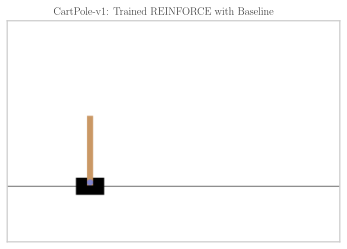

G_0 = 500.00 | шагов: 500

Демонстрация: Hopper-v5 (обученный REINFORCE)


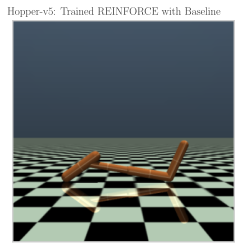

G_0 = 729.74 | шагов: 1000



In [6]:
# =====================================================================
# REINFORCE
# =====================================================================

# -------------------------------------------------------------
# Анимация CartPole-v1, REINFORCE with Baseline
# -------------------------------------------------------------
print("Демонстрация: CartPole-v1 (обученный REINFORCE)")
env = gym.make("CartPole-v1", render_mode="rgb_array")
state, info = env.reset(seed=SEED)
episode_return = 0.0
episode_steps = 0

fig, ax = plt.subplots(figsize=(6, 4))
img = ax.imshow(env.render())
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(r"CartPole-v1: Trained REINFORCE with Baseline", fontsize=11)

display_handle = display.display(fig, display_id=True)

for _ in range(500):
    # Детерминированный выбор наиболее вероятного действия
    action = res_cartpole_baseline["agent"].select_action(state, evaluate=True)
    state, reward, terminated, truncated, info = env.step(action)
    episode_return += reward
    episode_steps += 1
    
    img.set_data(env.render())
    display_handle.update(fig)
    
    if terminated or truncated:
        break

plt.close(fig)
env.close()
print(f"G_0 = {episode_return:.2f} | шагов: {episode_steps}\n")


# -------------------------------------------------------------
# Анимация Hopper-v5, REINFORCE with Baseline
# -------------------------------------------------------------
print("Демонстрация: Hopper-v5 (обученный REINFORCE)")
env = gym.make(ENV_ID_HOPPER, render_mode="rgb_array", **hopper_kwargs)
state, info = env.reset(seed=SEED)
episode_return = 0.0
episode_steps = 0

fig, ax = plt.subplots(figsize=(6, 4))
img = ax.imshow(env.render())
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(r"Hopper-v5: Trained REINFORCE with Baseline", fontsize=11)

display_handle = display.display(fig, display_id=True)

for _ in range(1000):
    # evaluate=True: выбор mu(s) непрерывной гауссовой стратегии без шума
    action = res_hopper_baseline["agent"].select_action(state, evaluate=True)
    state, reward, terminated, truncated, info = env.step(action)
    episode_return += reward
    episode_steps += 1
    
    img.set_data(env.render())
    display_handle.update(fig)
    
    if terminated or truncated:
        break

plt.close(fig)
env.close()
print(f"G_0 = {episode_return:.2f} | шагов: {episode_steps}\n")